# 06 · Final Comparison and Test Results

We compare all models **on the same validation engines and the same test engines**:
* **Baseline** — always predicts the average training RUL (every real model must beat this)
* **Elastic Net**, **Random Forest**, **XGBoost** — results saved by notebooks 03 – 05

The best model is chosen on **validation**, and only then reported on the **test set**.

> 💡 Cells marked with **⋯** are hidden because they only contain plotting or helper code. Click them to expand.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import load_features, evaluate, plot_test, stage_table, savefig, COLORS, RESULTS

MODEL_NAMES = ["Elastic Net", "Random Forest", "XGBoost"]
slug = lambda m: m.lower().replace(" ", "_")

train, test, FEATURES = load_features()
val_preds = {m: pd.read_csv(RESULTS / f"{slug(m)}_val_predictions.csv") for m in MODEL_NAMES}
test_preds = {m: pd.read_csv(RESULTS / f"{slug(m)}_test_predictions.csv") for m in MODEL_NAMES}

# Baseline: the mean RUL of the training engines
val = val_preds["XGBoost"][["unit", "cycle", "RUL_raw", "RUL"]]
val_preds["Baseline"] = val.assign(predicted=train.loc[train["split"] == "train", "RUL"].mean())
test_preds["Baseline"] = test_preds["XGBoost"][["unit", "RUL_raw", "RUL"]].assign(predicted=train["RUL"].mean())
ALL = ["Baseline"] + MODEL_NAMES

## 1. Validation results (20 engines, every cycle)

In [4]:
val_table = pd.DataFrame({m: evaluate(val_preds[m]["RUL"], val_preds[m]["predicted"]) for m in ALL}).T
best = val_table.drop("Baseline")["RMSE"].idxmin()
print("🏆 Best model on validation:", best)
val_table

🏆 Best model on validation: XGBoost


,RMSE,MAE,R2
Baseline,41.72,36.93,-0.000
Elastic Net,15.04,12.01,0.870
Random Forest,10.34,6.77,0.939
XGBoost,9.60,6.05,0.947


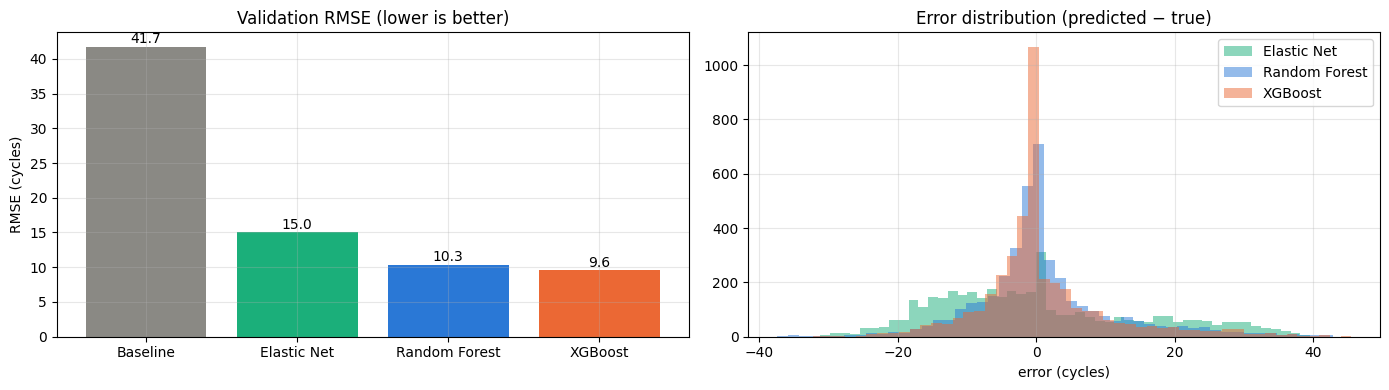

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(val_table.index, val_table["RMSE"], color=[COLORS[m] for m in val_table.index])
for i, v in enumerate(val_table["RMSE"]):
    ax[0].text(i, v + 0.5, f"{v:.1f}", ha="center")
ax[0].set(title="Validation RMSE (lower is better)", ylabel="RMSE (cycles)")
for m in MODEL_NAMES:
    ax[1].hist(val_preds[m]["predicted"] - val_preds[m]["RUL"], bins=50, alpha=0.5, color=COLORS[m], label=m)
ax[1].set(title="Error distribution (predicted − true)", xlabel="error (cycles)"); ax[1].legend()
savefig("06_validation_comparison")

## 2. Official NASA test set (100 engines)
The model was picked **before** looking at these numbers. The other models are shown only for reference.

In [6]:
test_table = pd.DataFrame({m: evaluate(test_preds[m]["RUL"], test_preds[m]["predicted"]) for m in ALL}).T
test_table.to_csv(RESULTS / "final_test_results.csv")
val_table.to_csv(RESULTS / "final_validation_results.csv")
test_table

,RMSE,MAE,R2
Baseline,41.94,34.83,-0.095
Elastic Net,16.13,13.14,0.838
Random Forest,11.44,8.27,0.918
XGBoost,10.14,7.40,0.936


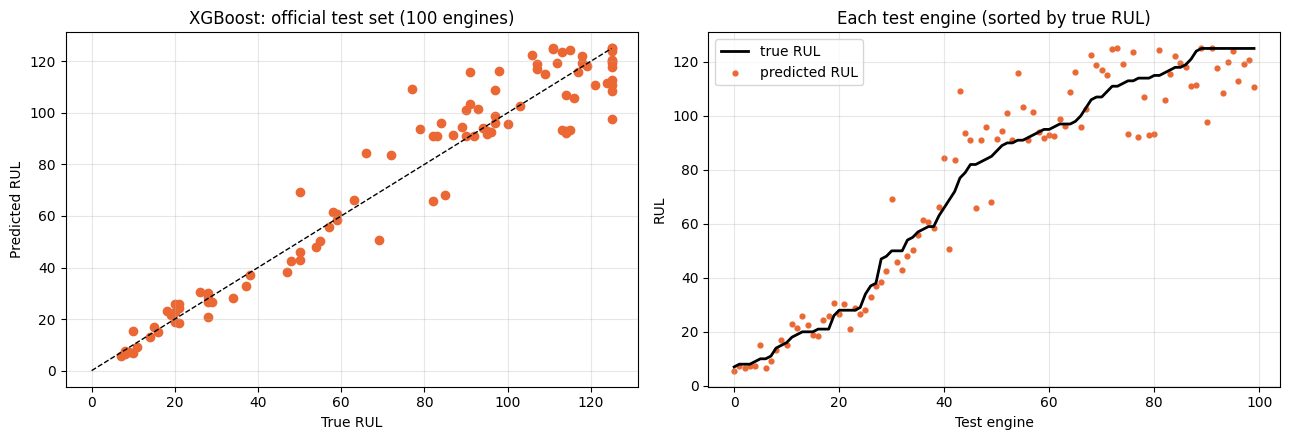

In [7]:
plot_test(best, test_preds[best]["RUL"], test_preds[best]["predicted"], "06_best_model_test")

## 3. Do engineered features help? (validation RMSE)

In [8]:
ablation = pd.concat([pd.read_csv(RESULTS / f"{slug(m)}_raw_vs_engineered.csv") for m in MODEL_NAMES]).set_index("Model")
ablation["with_engineered_features_val_RMSE"] = val_table.loc[MODEL_NAMES, "RMSE"]
ablation["improvement %"] = (100 * (1 - ablation.iloc[:, 1] / ablation.iloc[:, 0])).round(1)
ablation

,raw_sensors_only_val_RMSE,with_engineered_features_val_RMSE,improvement %
Model,,,
Elastic Net,17.96,15.04,16.3
Random Forest,15.98,10.34,35.3
XGBoost,15.53,9.60,38.2


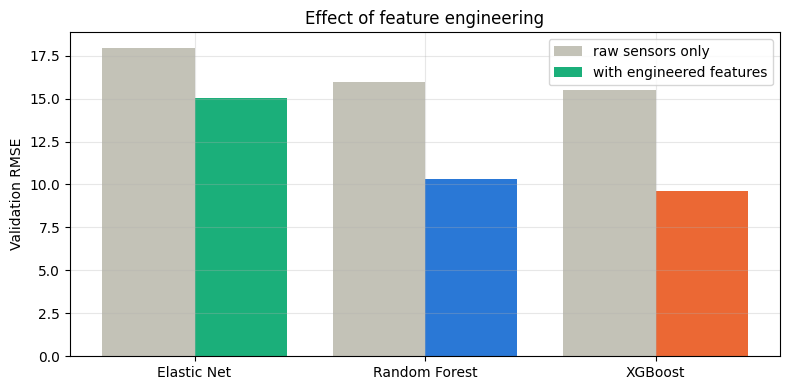

In [9]:
x = np.arange(len(MODEL_NAMES))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, ablation.iloc[:, 0], 0.4, color="#c3c2b7", label="raw sensors only")
plt.bar(x + 0.2, ablation.iloc[:, 1], 0.4, color=[COLORS[m] for m in MODEL_NAMES], label="with engineered features")
plt.xticks(x, MODEL_NAMES); plt.ylabel("Validation RMSE"); plt.title("Effect of feature engineering"); plt.legend()
savefig("06_feature_engineering_effect")

## 4. Early vs late life (validation)

In [10]:
stages = pd.concat({m: stage_table(val_preds[m]["RUL_raw"], val_preds[m]["RUL"], val_preds[m]["predicted"]) for m in ALL})
stages["RMSE"].unstack()

Stage,early (RUL > 100),late (RUL ≤ 100)
Baseline,35.67,47.07
Elastic Net,12.51,17.22
Random Forest,8.01,12.26
XGBoost,7.33,11.45


## 5. Conclusion
| Model | Validation RMSE | Test RMSE | Test MAE | Test R² |
|---|---:|---:|---:|---:|
| Baseline (average) | 41.72 | 41.94 | 34.83 | −0.10 |
| Elastic Net | 15.04 | 16.13 | 13.14 | 0.84 |
| Random Forest | 10.34 | 11.44 | 8.27 | 0.92 |
| **XGBoost (best)** | **9.60** | **10.14** | **7.40** | **0.94** |

* **Best model: XGBoost.** On the 100 official test engines it is off by **≈ 7 cycles on average** (MAE 7.40, RMSE 10.14),
  compared with ≈ 35 cycles for the baseline. Random Forest is close behind (≈ 1 cycle worse).
* **Feature engineering works:** engineered features cut the error by **≈ 38 % (XGBoost)** and **≈ 35 % (Random Forest)**
  compared with raw sensors only.
* **Most useful feature type:** `_dev` — each sensor's drift from the engine's **own healthy start** (≈ 80 % of tree importance).
* **Late life is harder:** errors are bigger when RUL ≤ 100. Early life looks "easy" only because the target is capped at 125.

**Limitations:** only FD001 (1 operating condition, 1 fault type, simulated data); one 80/20 engine split; rolling windows react
with a small delay; the cap of 125 is a modelling choice.

**Next step (Phase 2 — required by the project brief):** train a **sequence model (LSTM / 1D-CNN)** directly on windows of raw
sensor readings, with the same split and target, and compare it with XGBoost.